## Pandas analysis

This exercise consists in analyzing a dataset containg timing information from a series of Time-to-Digital-Converters (TDC) implemented in a couple of FPGAs. Each measurement (i.e. each row of the input file) consists of a flag that specifies the type of message ('HEAD', which in this case is always 1), two addresses of the TDC providing the signal ('FPGA' and 'TDC_CHANNEL'), and the timing information ('ORBIT_CNT', 'BX_COUNTER', and 'TDC_MEAS'). Each TDC count corresponds to 25/30 ns, whereas a unit of BX_COUNTER corresponds to 25 ns, and the ORBIT_CNT is increased every 'x' BX_COUNTER. This allows to store the time in a similar way to hours, minutes and seconds.

In [12]:
import pandas as pd
import random as random

In [1]:
# If you didn't download it yet, please get the relevant file now!
!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/

--2026-11-19 08:36:43--  https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt
Resolving www.dropbox.com (www.dropbox.com)... 162.125.69.18, 2620:100:6025:18::a27d:4512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.69.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/pkkpoxlm7beasryexpdf8/data_000637.txt?rlkey=rkm2em1v57hewglzelmin21c9 [following]
--2026-11-19 08:36:43--  https://www.dropbox.com/scl/fi/pkkpoxlm7beasryexpdf8/data_000637.txt?rlkey=rkm2em1v57hewglzelmin21c9
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc398e270129a7e03ecba8262fec.dl.dropboxusercontent.com/cd/0/inline/DMPgFfIH7jpN6hRcISbN2s7RpDzXPLM7U0y-cRTSd3BFWZfLagCfw_HLVHOTWF8Bwtm4tv4Aw15bfaQkDXEHh8fefDqkyJ4e-DrWZoT2hG0ShIVTxCHwrZqLha7LZNNrwrA/file# [following]
--2026-11-19 08:36:44--  https://uc398e270129a7e03ecba8262fec.dl.dropboxusercontent.com/cd/0/inline/DMPgFfIH7j

1\. Create a Pandas DataFrame reading N rows of the 'data_000637.txt' dataset. Choose N to be smaller than or equal to the maximum number of rows and larger that 10k.

2\. Find out the number of BX in a ORBIT (the value 'x').

3\. Find out how much the data taking lasted. You can either make an estimate based on the fraction of the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

4\. Create a new column with the absolute time in ns (as a combination of the other three columns with timing information).

5\. Replace the values (all 1) of the HEAD column randomly with 0 or 1.

6\. Create a new DataFrame that contains only the rows with HEAD=1.

7\. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

8\. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)

9\. Count the number of unique orbits. Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139

In [9]:
file_name = "data_000637.txt.1"
data = pd.read_csv(file_name)
data.head()
# ultimas tres columnas son medidas de horas minutos y segundos 5 aunque en realidad no lo son

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
0,1,0,123,3869200167,2374,26
1,1,0,124,3869200167,2374,27
2,1,0,63,3869200167,2553,28
3,1,0,64,3869200167,2558,19
4,1,0,64,3869200167,2760,25


In [19]:
# 1. Create a Pandas DataFrame reading N rows of the data...
max_pdf = data.shape[0]
tenk = 1e4
N = random.randint(tenk + 1, max_pdf)
N_data = data[:N]

In [33]:
# 2. Find out the number of BX in a ORBIT (the value 'x').
result = data.groupby('ORBIT_CNT')["BX_COUNTER"].count()
result

ORBIT_CNT
3869200167     43
3869200168     85
3869200169    127
3869200170     98
3869200171    109
3869200172     89
3869200173     88
3869200174    128
3869200175    128
3869200176     51
3869200177    111
3869200178     94
3869200179    128
3869200180     85
3869200181    118
3869200182     58
3869200183    123
3869200184     62
3869200185    135
3869200186     95
3869200187     92
3869200188    128
3869200189     38
3869200190     86
3869200191    138
3869200192     67
3869200193    147
3869200194    164
3869200195     77
3869200196     59
             ... 
3869211142    111
3869211143    136
3869211144    153
3869211145    165
3869211146    118
3869211147    130
3869211148    210
3869211149    149
3869211150    148
3869211151    175
3869211152    180
3869211153    127
3869211154    141
3869211155    240
3869211156    190
3869211157     95
3869211158    160
3869211159    166
3869211160    154
3869211161    215
3869211162    149
3869211163    189
3869211164    216
3869211165    251


In [ ]:
# 3. Find out how much the data taking lasted. You can either make an estimate based on the fraction of
# the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

In [ ]:
# 4.  Create a new column with the absolute time in ns 
# (as a combination of the other three columns with timing information).

In [73]:
# 5. Replace the values (all 1) of the HEAD column randomly with 0 or 1.
p = pd.DataFrame(data["HEAD"].replace(1, random.randint(0,1)))
p.head(15)

,HEAD
0,1
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


In [72]:
# 6. Create a new DataFrame that contains only the rows with HEAD=1.
data_head = pd.DataFrame(data["HEAD"])
data_head.head(10)

,HEAD
0,1
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


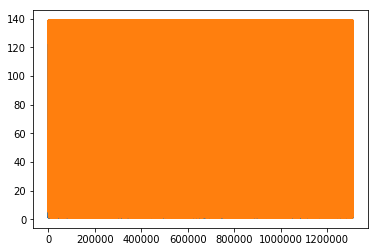

In [108]:
# 7. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

oness = data.loc[data["FPGA"] == 1]
oness["TDC_CHANNEL"].plot()

t= data.loc[data["FPGA"] == 0]
t["TDC_CHANNEL"].plot()

In [ ]:
# 8. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)




In [91]:
# 9. Count the number of unique orbits. 
# Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139
result = pd.DataFrame(data.groupby('TDC_CHANNEL')["ORBIT_CNT"].nunique())
result.loc[result["TDC_CHANNEL"] == 139, ["ORBIT_CNT"]]

KeyError: 'TDC_CHANNEL'